## Assignment 9

In [1]:
import time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (
    GCNConv, GINConv, SAGEConv, GATConv,
    global_mean_pool, global_add_pool, global_max_pool
)
from torch_geometric.utils import to_networkx

BASELINE_GCN_HIDDEN = 128
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device(
  "cuda" if torch.cuda.is_available()
  else "mps" if torch.backends.mps.is_available()
  else "cpu"
)
print("Device:", DEVICE)

Device: mps


/Users/alegator1209/Documents/KSE/term-4/ml/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
proteins = TUDataset(root="data/TUDataset", name="PROTEINS")
enzymes = TUDataset(root="data/TUDataset", name="ENZYMES")

In [3]:
print(enzymes)
print("Number of graphs:", len(enzymes))
print("Node features:", enzymes.num_node_features)
print("Classes:", enzymes.num_classes)

data = enzymes[0]
print(data)
print("x:", data.x.shape)
print("edge_index:", data.edge_index.shape)
print("y:", data.y)
print("nodes:", data.num_nodes, "edges:", data.num_edges)

ENZYMES(600)
Number of graphs: 600
Node features: 3
Classes: 6
Data(edge_index=[2, 168], x=[37, 3], y=[1])
x: torch.Size([37, 3])
edge_index: torch.Size([2, 168])
y: tensor([5])
nodes: 37 edges: 168


Class mapping: {0: 'EC1 oxidoreductase', 1: 'EC2 transferase', 2: 'EC3 hydrolase', 3: 'EC4 lyase', 4: 'EC5 isomerase', 5: 'EC6 ligase'}
Dataset properties
Graphs: 600
Classes: 6
Node features per node: 3
Total nodes: 19580
Total stored edges: 74564
Class proportions:


,proportion
class_name,
EC1 oxidoreductase,0.166667
EC2 transferase,0.166667
EC3 hydrolase,0.166667
EC4 lyase,0.166667
EC5 isomerase,0.166667
EC6 ligase,0.166667


,graph_id,label,num_nodes,num_edges,class_name
count,600.000000,600.00000,600.000000,600.000000,600
unique,NaN,NaN,NaN,NaN,6
top,NaN,NaN,NaN,NaN,EC1 oxidoreductase
freq,NaN,NaN,NaN,NaN,100
mean,299.500000,2.50000,32.633333,124.273333,NaN
std,173.349358,1.70925,15.288507,51.041166,NaN
min,0.000000,0.00000,2.000000,2.000000,NaN
25%,149.750000,1.00000,22.000000,86.000000,NaN
50%,299.500000,2.50000,32.000000,120.000000,NaN
75%,449.250000,4.00000,41.000000,164.000000,NaN


Node-feature matrix: (19580, 3)
Node-feature range: 0.0 to 1.0
Zero fraction: 0.667


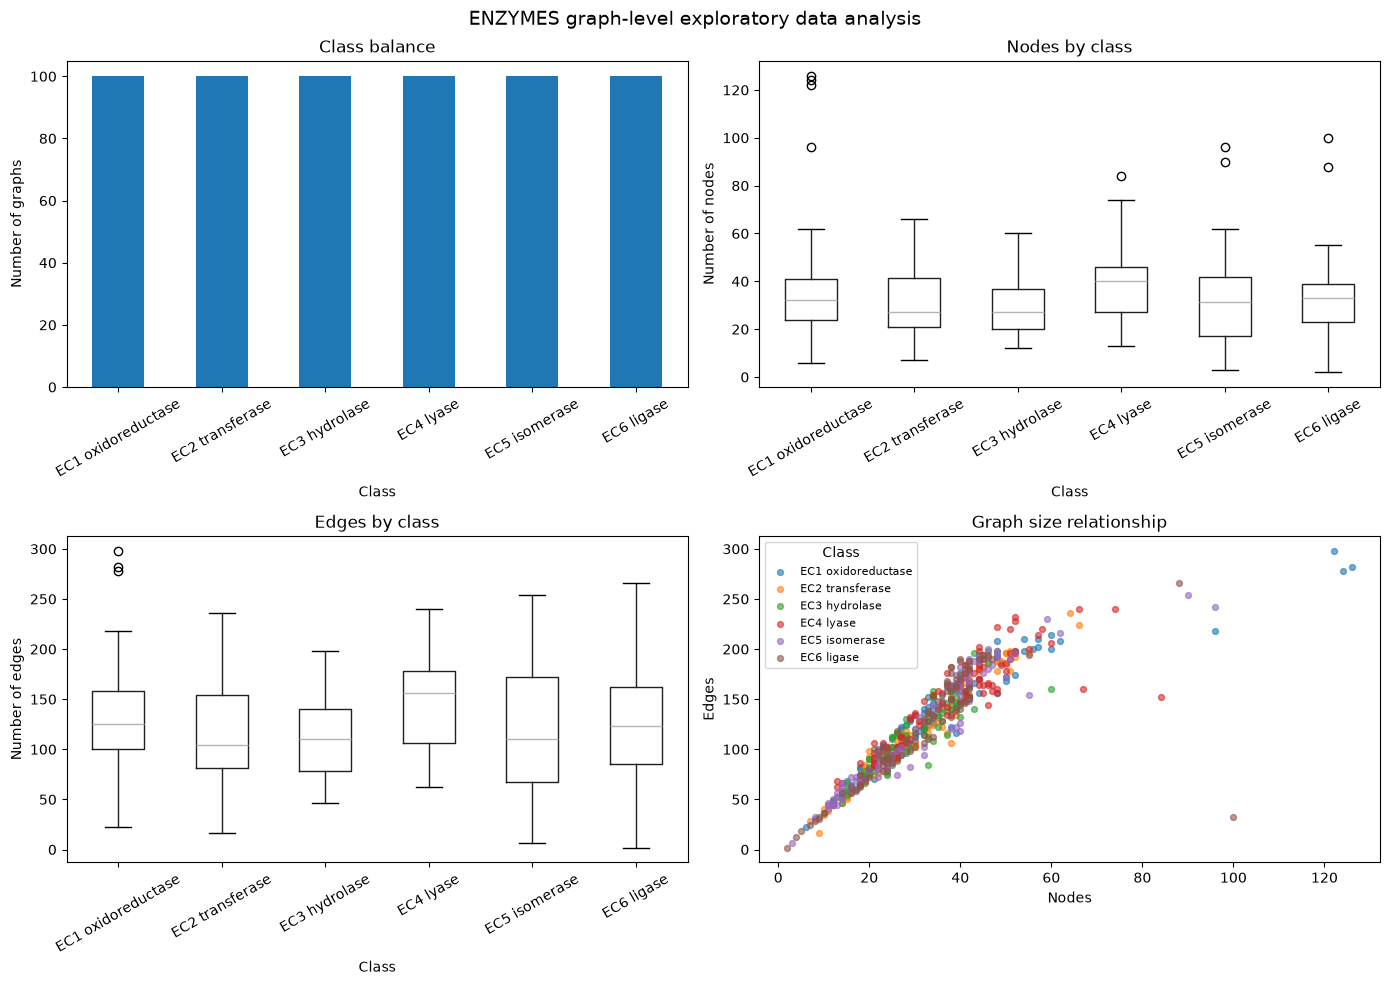

In [4]:
records = []
for i, g in enumerate(enzymes):
    records.append({
        "graph_id": i,
        "label": int(g.y.item()),
        "num_nodes": g.num_nodes,
        "num_edges": g.num_edges
    })

graph_df = pd.DataFrame(records)
# ENZYMES labels 0..5 correspond to the six top-level EC classes (EC 1 .. EC 6).
CLASS_NAMES = {
    0: "EC1 oxidoreductase",
    1: "EC2 transferase",
    2: "EC3 hydrolase",
    3: "EC4 lyase",
    4: "EC5 isomerase",
    5: "EC6 ligase",
}
graph_df["class_name"] = pd.Categorical(
    graph_df["label"].map(CLASS_NAMES),
    categories=list(CLASS_NAMES.values())
)
assert graph_df["class_name"].notna().all(), "Unexpected class label found"
print("Class mapping:", CLASS_NAMES)

print("Dataset properties")
print("Graphs:", len(enzymes))
print("Classes:", enzymes.num_classes)
print("Node features per node:", enzymes.num_node_features)
print("Total nodes:", int(graph_df["num_nodes"].sum()))
print("Total stored edges:", int(graph_df["num_edges"].sum()))
print("Class proportions:")
display(graph_df["class_name"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
display(graph_df.describe(include="all"))

# Concatenate node features to inspect their range and sparsity.
all_node_features = torch.cat([g.x for g in enzymes], dim=0).numpy()
print("Node-feature matrix:", all_node_features.shape)
print("Node-feature range:", float(all_node_features.min()), "to", float(all_node_features.max()))
print("Zero fraction:", round(float((all_node_features == 0).mean()), 3))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
graph_df["class_name"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="tab:blue")
axes[0, 0].set(title="Class balance", xlabel="Class", ylabel="Number of graphs")
axes[0, 0].tick_params(axis="x", rotation=30)
graph_df.boxplot(column="num_nodes", by="class_name", ax=axes[0, 1], grid=False, rot=30)
axes[0, 1].set(title="Nodes by class", xlabel="Class", ylabel="Number of nodes")
graph_df.boxplot(column="num_edges", by="class_name", ax=axes[1, 0], grid=False, rot=30)
axes[1, 0].set(title="Edges by class", xlabel="Class", ylabel="Number of edges")
for category, group in graph_df.groupby("class_name", observed=True):
    axes[1, 1].scatter(group["num_nodes"], group["num_edges"], s=18, alpha=0.6, label=category)
axes[1, 1].set(title="Graph size relationship", xlabel="Nodes", ylabel="Edges")
axes[1, 1].legend(title="Class", fontsize=8)
fig.suptitle("ENZYMES graph-level exploratory data analysis", fontsize=14)
plt.tight_layout()
plt.show()

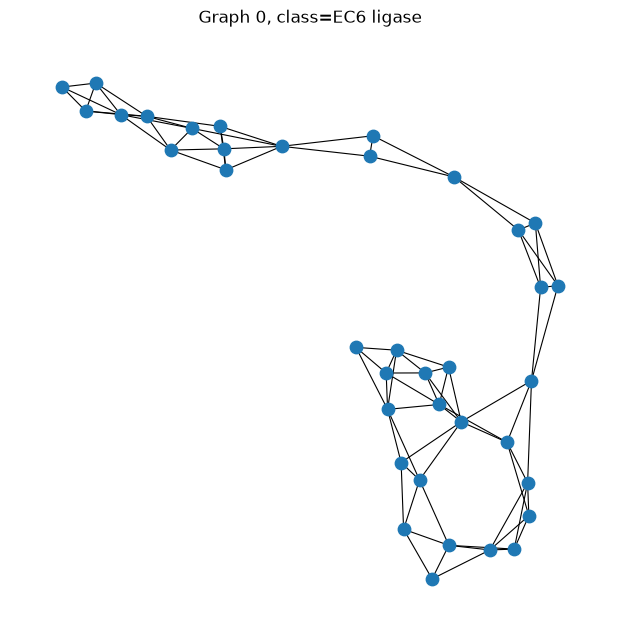

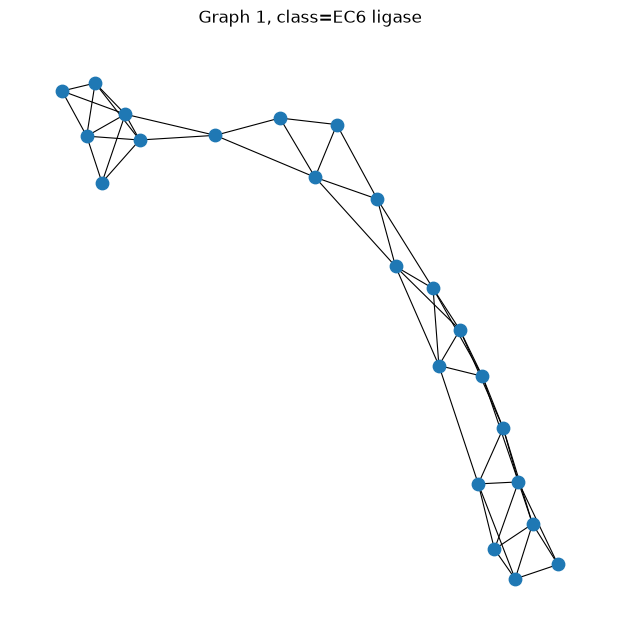

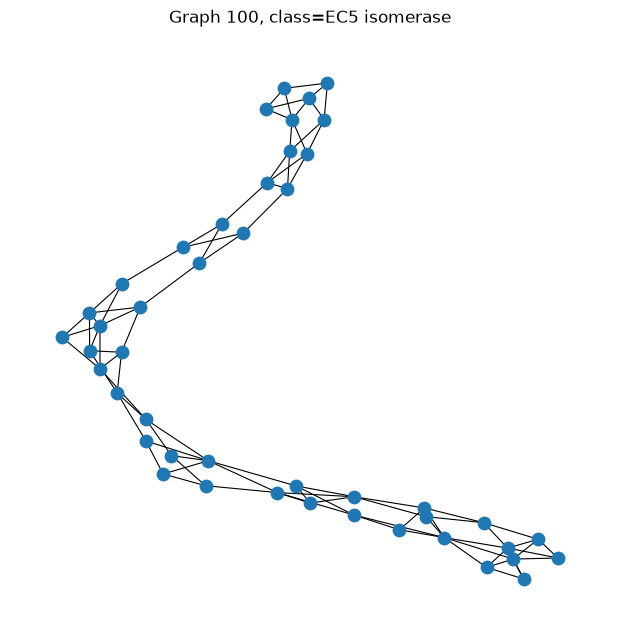

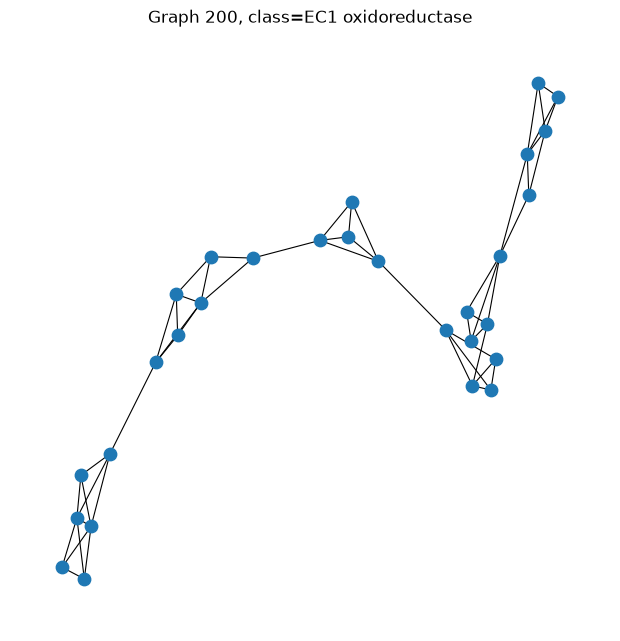

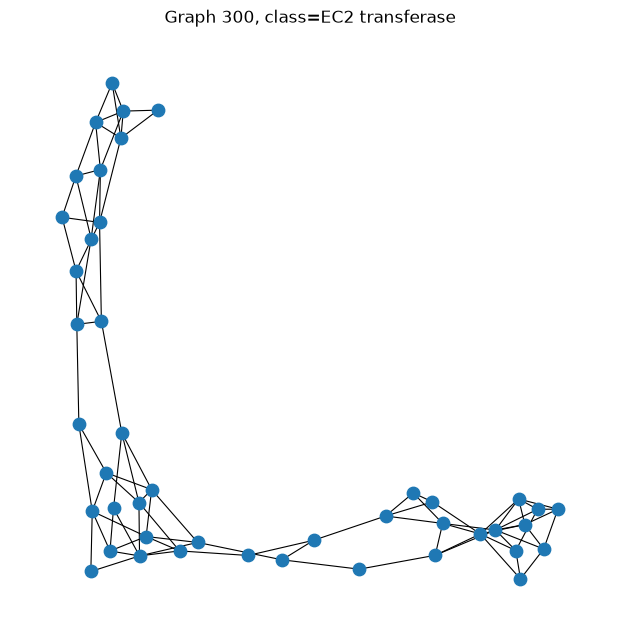

In [5]:
def plot_graph(data, title=None):
    G = to_networkx(data, to_undirected=True)
    plt.figure(figsize=(6,6))
    pos = nx.spring_layout(G, seed=RANDOM_STATE)
    nx.draw(G, pos, node_size=80, width=0.8, with_labels=False)
    if title:
        plt.title(title)
    plt.show()

# Display examples from both graph classes. The node positions are for visualization only;
# the GNN receives the original edge_index representation.
for idx in [0, 1, 100, 200, 300]:
    plot_graph(enzymes[idx], f"Graph {idx}, class={CLASS_NAMES[int(enzymes[idx].y.item())]}")

In [6]:
graph_index = 0
one_graph = enzymes[graph_index]

print("Graph label:", int(one_graph.y.item()), "→", CLASS_NAMES[int(one_graph.y.item())])
print("Number of nodes:", one_graph.num_nodes)
print("Stored edge rows:", one_graph.edge_index.shape[1])
print("Node-feature shape:", tuple(one_graph.x.shape))
print("Edge attributes:", getattr(one_graph, "edge_attr", None))

# A node table: one row per node and one column per input feature.
node_features = one_graph.x.cpu().numpy()
node_table = pd.DataFrame(
    node_features,
    columns=[f"x_{j}" for j in range(node_features.shape[1])]
)
node_table.insert(0, "node_id", np.arange(one_graph.num_nodes))
node_table["degree"] = np.bincount(
    one_graph.edge_index[0].cpu().numpy(), minlength=one_graph.num_nodes
)
display(node_table.head(12))

# edge_index is stored as two rows: source node and target node.
edge_array = one_graph.edge_index.t().cpu().numpy()
edge_table = pd.DataFrame(edge_array, columns=["source", "target"])
edge_table["source_degree"] = edge_table["source"].map(node_table.set_index("node_id")["degree"])
edge_table["target_degree"] = edge_table["target"].map(node_table.set_index("node_id")["degree"])
display(edge_table.head(20))

# For an undirected graph, opposite directions represent one relationship.
undirected_pairs = sorted({tuple(sorted((int(source), int(target)))) for source, target in edge_array})
print("Unique undirected relationships:", len(undirected_pairs))
display(pd.DataFrame(undirected_pairs, columns=["node_a", "node_b"]).head(20))


Graph label: 5 → EC6 ligase
Number of nodes: 37
Stored edge rows: 168
Node-feature shape: (37, 3)
Edge attributes: None


,node_id,x_0,x_1,x_2,degree
0,0,1.0,0.0,0.0,3
1,1,1.0,0.0,0.0,5
2,2,1.0,0.0,0.0,5
3,3,1.0,0.0,0.0,6
4,4,1.0,0.0,0.0,4
5,5,1.0,0.0,0.0,5
6,6,1.0,0.0,0.0,4
7,7,1.0,0.0,0.0,5
8,8,1.0,0.0,0.0,3
9,9,1.0,0.0,0.0,5


,source,target,source_degree,target_degree
0,0,1,3,5
1,0,2,3,5
2,0,3,3,6
3,1,0,5,3
4,1,2,5,5
5,1,3,5,6
6,1,24,5,4
7,1,27,5,5
8,2,0,5,3
9,2,1,5,5


Unique undirected relationships: 84


,node_a,node_b
0,0,1
1,0,2
2,0,3
3,1,2
4,1,3
5,1,24
6,1,27
7,2,3
8,2,27
9,2,28


In [7]:
indices = np.arange(len(enzymes))
labels = np.array([int(g.y.item()) for g in enzymes])

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, stratify=labels, random_state=RANDOM_STATE
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=RANDOM_STATE
)

train_dataset = enzymes[torch.tensor(train_idx)]
val_dataset   = enzymes[torch.tensor(val_idx)]
test_dataset  = enzymes[torch.tensor(test_idx)]

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))

420 90 90


# GCN Encoder

In [8]:
class GCNClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, dropout=0.2, pooling="mean"):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)
        self.pooling = pooling

    def pool(self, x, batch):
        if self.pooling == "mean":
            return global_mean_pool(x, batch)
        if self.pooling == "sum":
            return global_add_pool(x, batch)
        if self.pooling == "max":
            return global_max_pool(x, batch)
        raise ValueError("Unknown pooling")

    def encode(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        return self.pool(x, batch)

    def forward(self, x, edge_index, batch):
        z = self.encode(x, edge_index, batch)
        return self.classifier(self.dropout(z))

    def load(self, checkpoint):
      self.conv1.load_state_dict(checkpoint["conv1"])
      self.conv2.load_state_dict(checkpoint["conv2"])

      return self

    def freeze_encoder(self):
      self.conv1.requires_grad_(False)
      self.conv2.requires_grad_(False)

      return self


In [9]:
def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

gcn = GCNClassifier(
    enzymes.num_node_features,
    BASELINE_GCN_HIDDEN,
    enzymes.num_classes
).to(DEVICE)

print(gcn)
print("Trainable params:", count_trainable_parameters(gcn))

GCNClassifier(
  (conv1): GCNConv(3, 128)
  (conv2): GCNConv(128, 128)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=6, bias=True)
)
Trainable params: 17798


In [10]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, y_true, y_pred = 0.0, [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        y = batch.y.view(-1)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        y_true.extend(y.cpu().numpy())
        y_pred.extend(logits.argmax(1).detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, y_true, y_pred = 0.0, [], []

    for batch in loader:
        batch = batch.to(DEVICE)
        logits = model(batch.x, batch.edge_index, batch.batch)
        y = batch.y.view(-1)
        loss = F.cross_entropy(logits, y)

        total_loss += loss.item() * batch.num_graphs
        y_true.extend(y.cpu().numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }

def fit_model(model, train_loader, val_loader, epochs=50, lr=1e-3, weight_decay=1e-4):
    opt = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    history, best_state, best_f1 = [], None, -np.inf
    t0 = time.time()

    for epoch in range(1, epochs+1):
        tr = train_epoch(model, train_loader, opt)
        va = evaluate(model, val_loader)

        history.append({
            "epoch": epoch,
            **{f"train_{k}":v for k,v in tr.items()},
            **{f"val_{k}":v for k,v in va.items() if not k.startswith("y_")}
        })

        if va["macro_f1"] > best_f1:
            best_f1 = va["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        if epoch == 1 or epoch % 10 == 0:
            print(f"{epoch:03d} | train F1={tr['macro_f1']:.3f} | val F1={va['macro_f1']:.3f}")

    model.load_state_dict(best_state)
    return pd.DataFrame(history), time.time()-t0


001 | train F1=0.083 | val F1=0.046
010 | train F1=0.176 | val F1=0.135
020 | train F1=0.203 | val F1=0.143
030 | train F1=0.203 | val F1=0.168
040 | train F1=0.213 | val F1=0.163
050 | train F1=0.210 | val F1=0.192
060 | train F1=0.228 | val F1=0.229
070 | train F1=0.217 | val F1=0.204
080 | train F1=0.220 | val F1=0.216
090 | train F1=0.225 | val F1=0.213
100 | train F1=0.239 | val F1=0.210


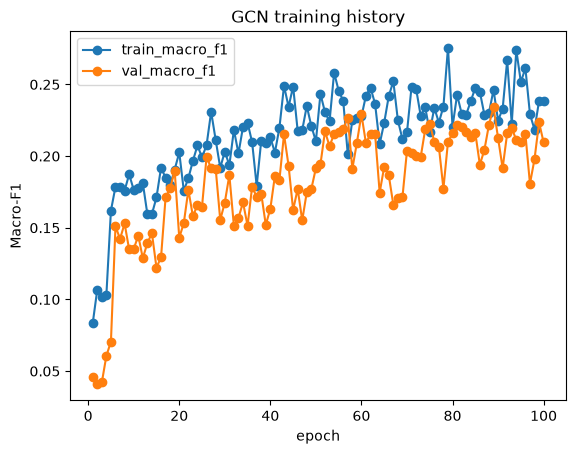

In [11]:
history_gcn, time_gcn = fit_model(gcn, train_loader, val_loader, epochs=100)
history_gcn.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GCN training history")
plt.show()

![](https://tr.rbxcdn.com/180DAY-9838d72aafc9656c1a97fd56d1e7bbd1/420/420/BackAccessory/Webp/noFilter)

In [12]:
ckpt = torch.load("checkpoints/proteins_gcn_encoder.pt", map_location=DEVICE)

gcn_frozen = GCNClassifier(
    enzymes.num_node_features,
    BASELINE_GCN_HIDDEN,
    enzymes.num_classes
).to(DEVICE).load(ckpt).freeze_encoder()

print(gcn_frozen)
print("Trainable params:", count_trainable_parameters(gcn_frozen))

GCNClassifier(
  (conv1): GCNConv(3, 128)
  (conv2): GCNConv(128, 128)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=6, bias=True)
)
Trainable params: 774


001 | train F1=0.071 | val F1=0.048
010 | train F1=0.220 | val F1=0.085
020 | train F1=0.175 | val F1=0.132
030 | train F1=0.166 | val F1=0.167
040 | train F1=0.190 | val F1=0.141
050 | train F1=0.171 | val F1=0.170
060 | train F1=0.184 | val F1=0.154
070 | train F1=0.186 | val F1=0.169
080 | train F1=0.194 | val F1=0.190
090 | train F1=0.193 | val F1=0.172
100 | train F1=0.207 | val F1=0.170


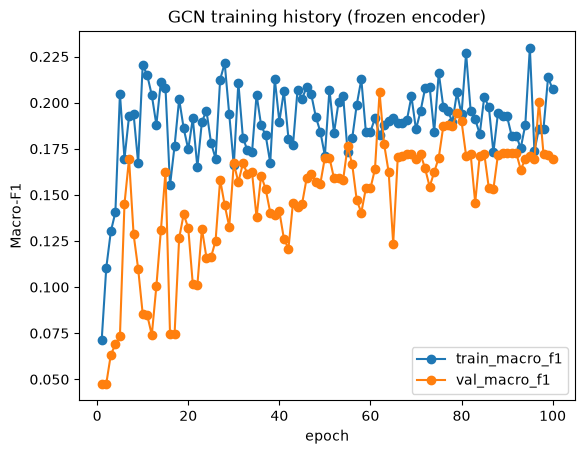

In [13]:
history_gcn_frozen, time_gcn_frozen = fit_model(gcn_frozen, train_loader, val_loader, epochs=100)
history_gcn_frozen.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GCN training history (frozen encoder)")
plt.show()

![](https://media.tenor.com/W8ImMlYbR2EAAAAe/byuntear-incrives-meme.png)

In [14]:
ckpt = torch.load("checkpoints/proteins_gcn_encoder.pt", map_location=DEVICE)

gcn_unfrozen = GCNClassifier(
    enzymes.num_node_features,
    BASELINE_GCN_HIDDEN,
    enzymes.num_classes
).to(DEVICE).load(ckpt)

print(gcn_unfrozen)
print("Trainable params:", count_trainable_parameters(gcn_unfrozen))

GCNClassifier(
  (conv1): GCNConv(3, 128)
  (conv2): GCNConv(128, 128)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=128, out_features=6, bias=True)
)
Trainable params: 17798


001 | train F1=0.072 | val F1=0.088
010 | train F1=0.226 | val F1=0.196
020 | train F1=0.207 | val F1=0.189
030 | train F1=0.246 | val F1=0.196
040 | train F1=0.210 | val F1=0.226
050 | train F1=0.243 | val F1=0.206
060 | train F1=0.248 | val F1=0.193
070 | train F1=0.222 | val F1=0.208
080 | train F1=0.247 | val F1=0.208
090 | train F1=0.236 | val F1=0.203
100 | train F1=0.248 | val F1=0.189


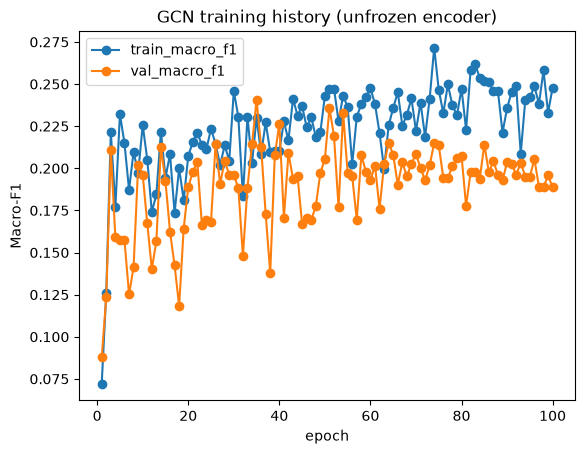

In [15]:
history_gcn_unfrozen, time_gcn_unfrozen = fit_model(gcn_unfrozen, train_loader, val_loader, epochs=100)
history_gcn_unfrozen.plot(x="epoch", y=["train_macro_f1", "val_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("GCN training history (unfrozen encoder)")
plt.show()

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQnI3qxSrI-reMvxdDiwixXBULzMPoHa-2FIgqI6d2NUuZ50spMl7-nkUg&s=10)

,best_train_macro_f1,best_val_macro_f1,best_val_epoch
Scratch,0.275626,0.233990,89.0
Frozen transfer,0.229819,0.205632,62.0
Fine-tuned transfer,0.271585,0.240611,35.0


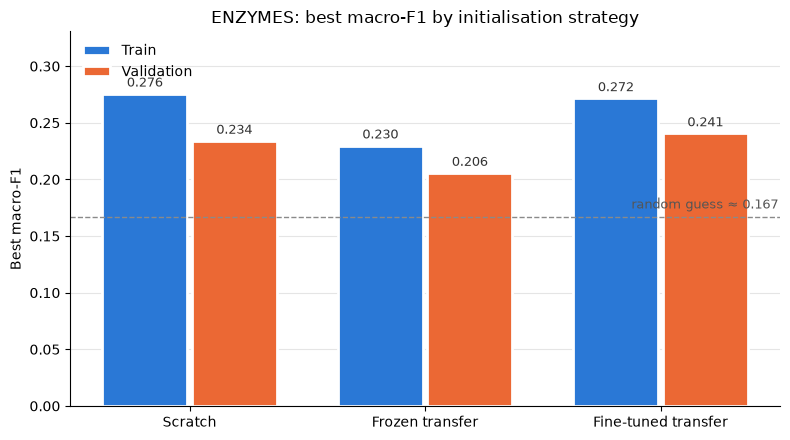

In [16]:
histories = {
    "Scratch": history_gcn,
    "Frozen transfer": history_gcn_frozen,
    "Fine-tuned transfer": history_gcn_unfrozen,
}

best_scores = pd.DataFrame({
    name: {
        "best_train_macro_f1": h["train_macro_f1"].max(),
        "best_val_macro_f1": h["val_macro_f1"].max(),
        "best_val_epoch": int(h.loc[h["val_macro_f1"].idxmax(), "epoch"]),
    }
    for name, h in histories.items()
}).T

display(best_scores)

TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"
RANDOM_F1 = 1 / enzymes.num_classes

x = np.arange(len(best_scores))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, column, label, color in [
    (-width / 2, "best_train_macro_f1", "Train", TRAIN_COLOR),
    (+width / 2, "best_val_macro_f1", "Validation", VAL_COLOR),
]:
    bars = ax.bar(x + offset, best_scores[column], width - 0.02, label=label,
                  color=color, edgecolor="white", linewidth=2)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, color="#333333")

ax.axhline(RANDOM_F1, color="#8a8a8a", linestyle="--", linewidth=1)
ax.text(len(x) - 0.5, RANDOM_F1 + 0.005, f"random guess ≈ {RANDOM_F1:.3f}",
        ha="right", va="bottom", fontsize=9, color="#555555")

ax.set_xticks(x, best_scores.index)
ax.set_ylabel("Best macro-F1")
ax.set_ylim(0, best_scores[["best_train_macro_f1", "best_val_macro_f1"]].to_numpy().max() * 1.2)
ax.set_title("ENZYMES: best macro-F1 by initialisation strategy")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

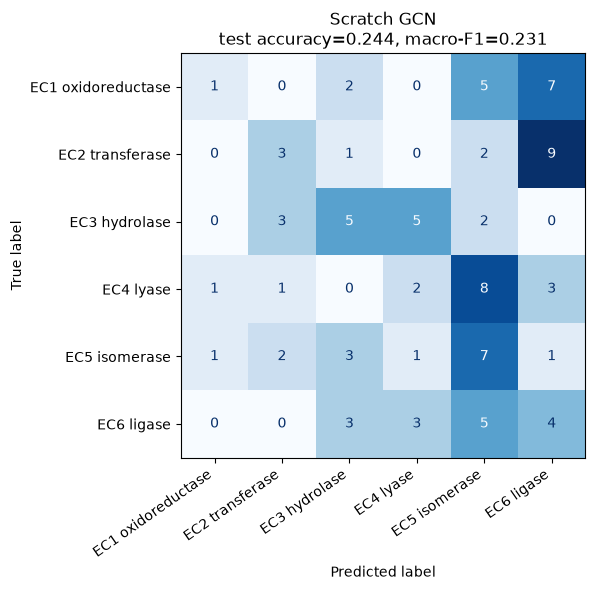

In [17]:
CLASS_LABELS = [CLASS_NAMES[i] for i in range(enzymes.num_classes)]

def plot_confusion(model, title, loader=test_loader):
    metrics = evaluate(model, loader)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        metrics["y_true"], metrics["y_pred"],
        labels=list(range(enzymes.num_classes)),
        display_labels=CLASS_LABELS,
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{title}\ntest accuracy={metrics['accuracy']:.3f}, macro-F1={metrics['macro_f1']:.3f}")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
    return metrics

test_metrics_scratch = plot_confusion(gcn, "Scratch GCN")

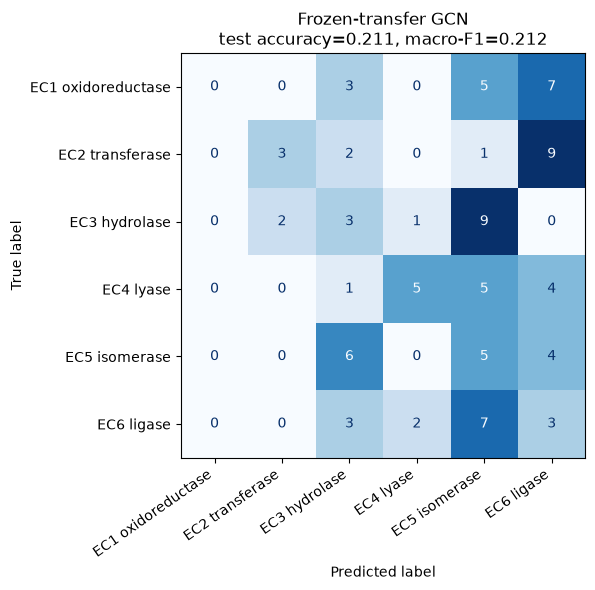

In [18]:
test_metrics_frozen = plot_confusion(gcn_frozen, "Frozen-transfer GCN")

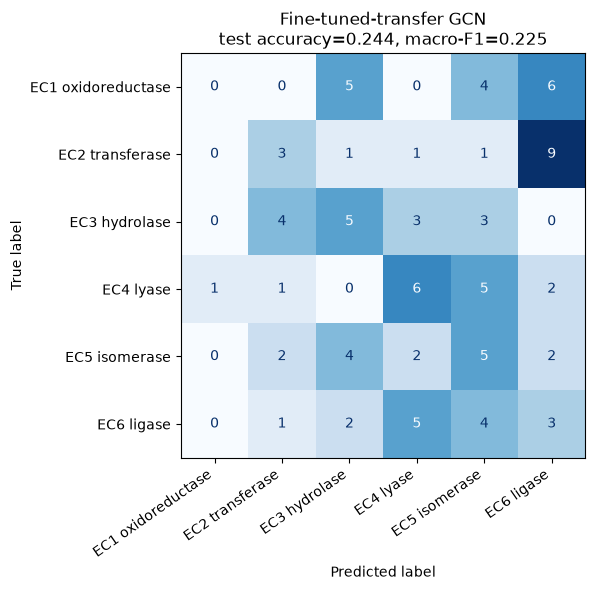

In [19]:
test_metrics_unfrozen = plot_confusion(gcn_unfrozen, "Fine-tuned-transfer GCN")

# Conclusions

1. Did transfer improve over random initialization? - Nah, quite the opposite. It seems the transfer introduced its own biases, e.g. excessive misclassification of EC3 hydrolase as EC5 Isomerase. If you think about it, that's expected. The goal of the PROTEIN encoder was to distinguish enzymes and non-enzymes. On the other hand, all entries of the ENZYMES dataset are already known to be, well, enzymes. Learned knowledge from the PROTEINs is just a noise for this problem.

2. Did freezing the encoder work as well as fine-tuning it? - No

3. Which ENZYMES classes are confused most often? - EC5 is often assigned where it shouldn't be, for all other classes except EC2. It's especially visible in frozen encoder EC3 row.

4. Are the PROTEINS and ENZYMES tasks sufficiently related for transfer to be useful? - No

5. Could the result be explained by the small dataset size or by class imbalance? - Class imbalance, no. Small dataset - yes. Only 100 enzymes per class. Another thing is the number of features. Enzymatic sites are often a small part of the larger secondary structure, or formed by residues from several secodnary structures. Relying just on the sequence of secondary structures without knowing what exactly residues compose them looks like a futile tasks to begin with.

6. What would change if the source and target node-feature dimensions were different? - Transfer learning could not work out of box. We would need to adapt, e.g. by mapping the data or introducing some input layer that transfers ENZYMES data into PROTEINS format or vice versa. 